# Felicidad, economía y bienestar en países del mundo

In [2]:
import glob
import re

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

## 1. Carga de los datos

In [3]:
frames = []
for path in sorted(glob.glob("WHR_*.csv")):
    df_year = pd.read_csv(path, encoding="utf-8-sig")
    df_year["year"] = int(re.search(r"(\d{4})", path).group(1))
    frames.append(df_year)

df = pd.concat(frames, ignore_index=True)
print(df.shape)
df.head()

(1367, 10)


,country,region,happiness_score,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption,year
0,Switzerland,Western Europe,7.587,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978,2015
1,Iceland,Western Europe,7.561,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145,2015
2,Denmark,Western Europe,7.527,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357,2015
3,Norway,Western Europe,7.522,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503,2015
4,Canada,North America and ANZ,7.427,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957,2015


In [4]:
df["year"].value_counts().sort_index()

year
2015    158
2016    157
2017    155
2018    156
2019    156
2020    153
2021    149
2022    146
2023    137
Name: count, dtype: int64

## 2. Filtro al año más reciente

In [5]:
ultimo_anio = df["year"].max()
df_reciente = df[df["year"] == ultimo_anio].copy()
print(f"Año más reciente: {ultimo_anio}  |  Países: {len(df_reciente)}")
df_reciente.head()

Año más reciente: 2023  |  Países: 137


,country,region,happiness_score,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption,year
1230,Finland,Western Europe,7.804,1.888,1.585,0.535,0.772,0.126,0.535,2023
1231,Denmark,Western Europe,7.586,1.949,1.548,0.537,0.734,0.208,0.525,2023
1232,Iceland,Western Europe,7.530,1.926,1.620,0.559,0.738,0.250,0.187,2023
1233,Israel,Middle East and North Africa,7.473,1.833,1.521,0.577,0.569,0.124,0.158,2023
1234,Netherlands,Western Europe,7.403,1.942,1.488,0.545,0.672,0.251,0.394,2023


In [8]:
print(df_reciente.columns.tolist())

['country', 'region', 'happiness_score', 'gdp_per_capita', 'social_support', 'healthy_life_expectancy', 'freedom_to_make_life_choices', 'generosity', 'perceptions_of_corruption', 'year']


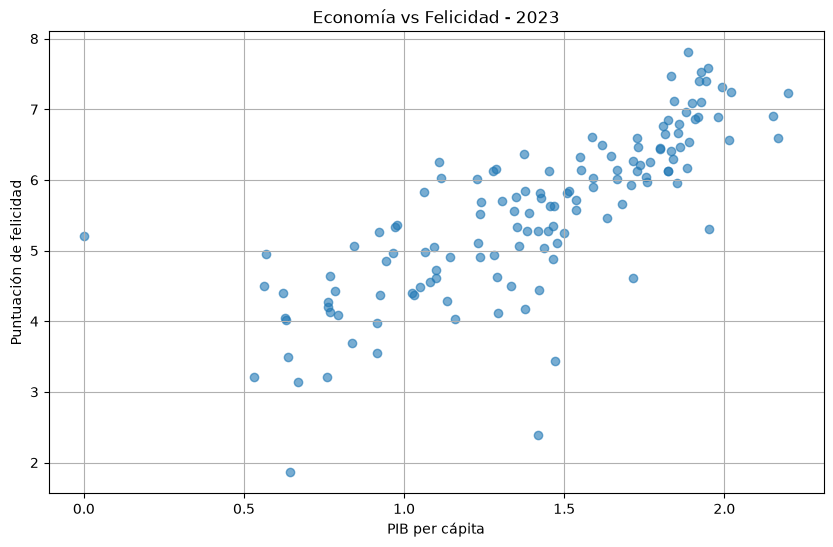

In [9]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_reciente["gdp_per_capita"],
    df_reciente["happiness_score"],
    alpha=0.6
)

plt.title(f"Economía vs Felicidad - {ultimo_anio}")
plt.xlabel("PIB per cápita")
plt.ylabel("Puntuación de felicidad")

plt.grid(True)
plt.show()

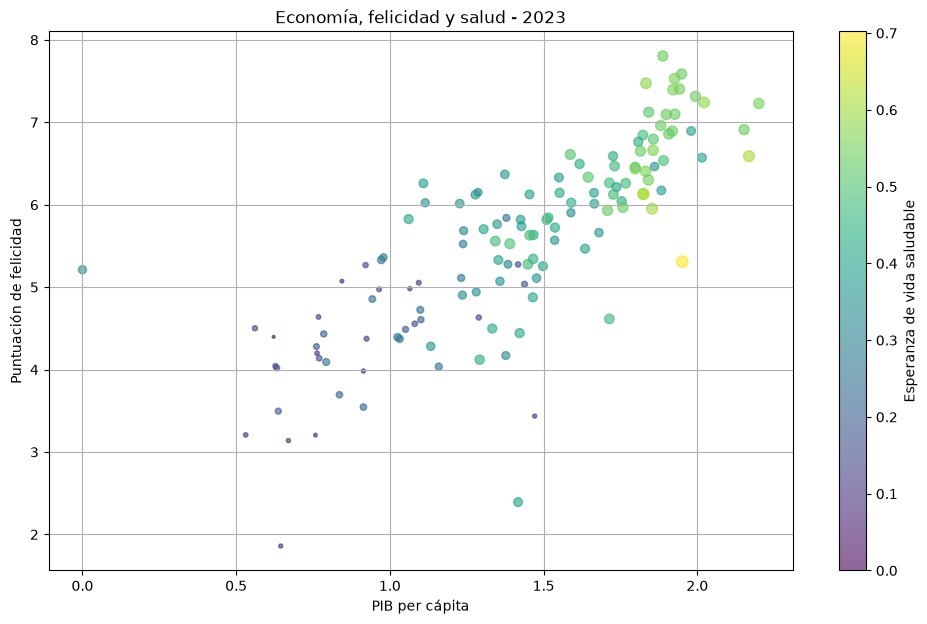

In [10]:
plt.figure(figsize=(12, 7))

plt.scatter(
    df_reciente["gdp_per_capita"],
    df_reciente["happiness_score"],
    s=df_reciente["healthy_life_expectancy"] * 100,
    c=df_reciente["healthy_life_expectancy"],
    alpha=0.6,
    cmap="viridis"
)

plt.colorbar(label="Esperanza de vida saludable")

plt.title(f"Economía, felicidad y salud - {ultimo_anio}")
plt.xlabel("PIB per cápita")
plt.ylabel("Puntuación de felicidad")

plt.grid(True)
plt.show()